Using Colab cache for faster access to the 'augmented-enhanced-pcos' dataset.
label
0    9144
1    6248
Name: count, dtype: int64
Hashing images to find augmented copies (one-time, ~1 min)...
15392 images -> 9425 independent groups (avg 1.6 near-copies per group)
10884 2004 2504
Epoch 1/5
341/341 ━━━━━━━━━━━━━━━━━━━━ 60s 147ms/step - accuracy: 0.9553 - auc: 0.9886 - loss: 0.1384 - val_accuracy: 0.4980 - val_auc: 0.8638 - val_loss: 1.5919
Epoch 2/5
341/341 ━━━━━━━━━━━━━━━━━━━━ 24s 70ms/step - accuracy: 0.9433 - auc: 0.9680 - loss: 0.2309 - val_accuracy: 0.7330 - val_auc: 0.9241 - val_loss: 0.8773
Epoch 3/5
341/341 ━━━━━━━━━━━━━━━━━━━━ 24s 70ms/step - accuracy: 0.9311 - auc: 0.9747 - loss: 0.1901 - val_accuracy: 0.9311 - val_auc: 0.9842 - val_loss: 0.2000
Epoch 4/5
341/341 ━━━━━━━━━━━━━━━━━━━━ 24s 70ms/step - accuracy: 0.9377 - auc: 0.9782 - loss: 0.1795 - val_accuracy: 0.5878 - val_auc: 0.7799 - val_loss: 1.7610
Epoch 5/5
341/341 ━━━━━━━━━━━━━━━━━━━━ 24s 70ms/step - accuracy: 0.9451 - a

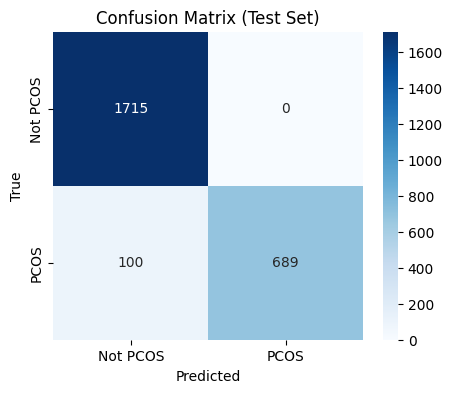

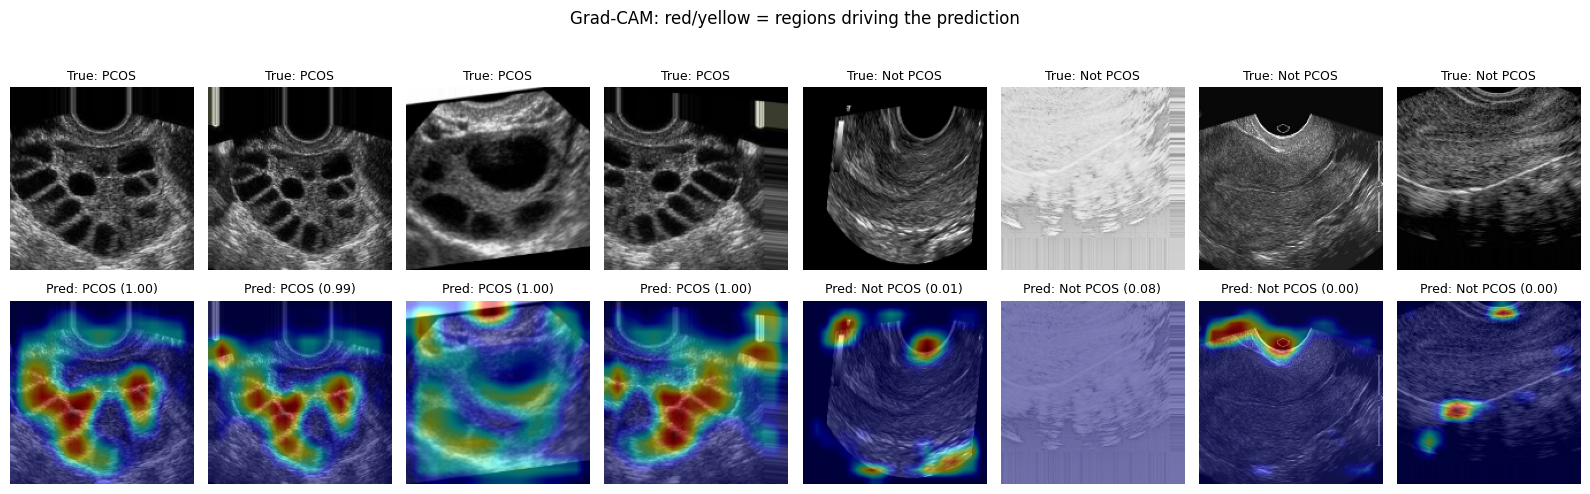

Saved artifact at 'saved_models/pcos_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 160, 160, 3), dtype=tf.float32, name='keras_tensor_92')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  133285921563536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133285928791952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133285928790800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133285928781968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133285928793104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133285928789840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133285928787152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133285928793296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133285928781584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133285928785616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1332

In [ ]:
# ============== 1. SETUP ==============
!pip install kagglehub tensorflow numpy pandas matplotlib scikit-learn seaborn opencv-python-headless scipy --quiet

import os, time, kagglehub
import numpy as np, pandas as pd
import tensorflow as tf
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import confusion_matrix, classification_report

tf.keras.utils.set_random_seed(42)
for g in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(g, True)

IMG_SIZE   = 160
BATCH      = 32
EPOCHS     = 5
TIME_LIMIT = 6 * 60

# ============== 2. DOWNLOAD & FIND DATA ==============
path = kagglehub.dataset_download("amritarajput54/augmented-enhanced-pcos")

def find_dataset_path(base):
    for root, dirs, _ in os.walk(base):
        low = [d.lower() for d in dirs]
        if 'infected' in low and 'notinfected' in low:
            return root
    raise FileNotFoundError("Could not find 'infected' and 'notinfected' folders.")

root = find_dataset_path(path)
CLASS_NAMES = ["Not PCOS", "PCOS"]
folder_map = {d: (1 if d.lower() == "infected" else 0)
              for d in os.listdir(root) if d.lower() in ("infected", "notinfected")}

rows = []
for folder, lab in folder_map.items():
    for f in os.listdir(os.path.join(root, folder)):
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            rows.append((os.path.join(root, folder, f), lab))
df = pd.DataFrame(rows, columns=["path", "label"])
print(df.label.value_counts())

# ============== 3. GROUP NEAR-DUPLICATES (anti-leakage) ==============
def dhash_bits(img_gray, size=8):
    small = cv2.resize(img_gray, (size + 1, size), interpolation=cv2.INTER_AREA)
    return (small[:, 1:] > small[:, :-1]).flatten().astype(np.uint8)

def invariant_hash(path):
    g = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    g = cv2.resize(g, (64, 64), interpolation=cv2.INTER_AREA)
    g = cv2.equalizeHist(g)                       # reduces brightness/contrast differences
    variants = []
    for k in range(4):
        r = np.rot90(g, k)
        variants += [r, np.fliplr(r)]             # 8 flip/rotation variants
    hashes = [dhash_bits(np.ascontiguousarray(v)) for v in variants]
    # canonical form = lexicographically smallest variant
    return min(hashes, key=lambda h: h.tobytes())

print("Hashing images to find augmented copies (one-time, ~1 min)...")
H = np.stack([invariant_hash(p) for p in df.path])

nn = NearestNeighbors(radius=0.10, metric="hamming", algorithm="brute").fit(H)  # <=6 of 64 bits differ
graph = nn.radius_neighbors_graph(H, mode="connectivity")
n_groups, groups = connected_components(csr_matrix(graph), directed=False)
df["group"] = groups
print(f"{len(df)} images -> {n_groups} independent groups "
      f"(avg {len(df)/n_groups:.1f} near-copies per group)")

# ============== 4. GROUP-AWARE SPLIT (~70/15/15) ==============
sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42)
trainval_idx, test_idx = next(sgkf.split(df, df.label, df.group))
trainval_df, test_df = df.iloc[trainval_idx], df.iloc[test_idx]

sgkf2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
tr_idx, va_idx = next(sgkf2.split(trainval_df, trainval_df.label, trainval_df.group))
train_df, val_df = trainval_df.iloc[tr_idx], trainval_df.iloc[va_idx]

assert not (set(train_df.group) & set(val_df.group)), "leak train/val"
assert not (set(train_df.group) & set(test_df.group)), "leak train/test"
print(len(train_df), len(val_df), len(test_df))

# ============== 5. DATA PIPELINE ==============
def make_ds(d, training=False):
    def load(p, y):
        img = tf.io.read_file(p)
        img = tf.image.decode_image(img, channels=3, expand_animations=False)
        img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
        return img, tf.cast(y, tf.float32)
    ds = tf.data.Dataset.from_tensor_slices((d.path.values, d.label.values))
    ds = ds.map(load, num_parallel_calls=tf.data.AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(2000, seed=42)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(train_df, True), make_ds(val_df), make_ds(test_df)

# ============== 6. CUSTOM CNN (from scratch) ==============
def conv_block(x, filters, pool=True, name=None):
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu", name=name)(x)
    if pool:
        x = layers.MaxPooling2D(2)(x)
    return x

def build_model():
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = layers.RandomFlip("horizontal_and_vertical")(inputs)
    x = layers.RandomRotation(0.1)(x)
    x = layers.Rescaling(1 / 255.0)(x)
    x = conv_block(x, 32)
    x = conv_block(x, 64)
    x = conv_block(x, 128)
    x = conv_block(x, 128, pool=False, name="last_conv")
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    model = tf.keras.Model(inputs, outputs, name="custom_pcos_cnn")
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss="binary_crossentropy",
                  metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])
    return model

model = build_model()

class TimeBudget(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None): self.t0 = time.time()
    def on_train_batch_end(self, batch, logs=None):
        if time.time() - self.t0 > TIME_LIMIT:
            print("\nTime budget reached. Stopping.")
            self.model.stop_training = True

t0 = time.time()
model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, verbose=1,
          callbacks=[TimeBudget(),
                     tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2,
                                                      restore_best_weights=True)])
print(f"Training time: {(time.time() - t0) / 60:.1f} min")

# ============== 7. HELD-OUT TEST EVALUATION ==============
probs  = model.predict(test_ds).ravel()
y_true = test_df.label.values
y_pred = (probs > 0.5).astype(int)
print(f"\nTest accuracy: {(y_pred == y_true).mean() * 100:.2f}%")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion Matrix (Test Set)")
plt.show()

# ============== 8. GRAD-CAM HEATMAPS ==============
grad_model = tf.keras.Model(model.input, [model.get_layer("last_conv").output, model.output])

def grad_cam(img_uint8):
    x = tf.convert_to_tensor(img_uint8[None, ...], tf.float32)
    with tf.GradientTape() as tape:
        fmap, pred = grad_model(x, training=False)
        score = pred[:, 0]
    grads   = tape.gradient(score, fmap)
    weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(weights * fmap, axis=-1))[0].numpy()
    cam = cam / (cam.max() + 1e-8)
    return cv2.resize(cam, (IMG_SIZE, IMG_SIZE)), float(pred[0, 0])

def load_img(p):
    return cv2.resize(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB), (IMG_SIZE, IMG_SIZE))

def show_examples(n_per_class=4):
    fig, axes = plt.subplots(2, n_per_class * 2, figsize=(4 * n_per_class, 5))
    col = 0
    for lab in [1, 0]:
        for p in test_df[test_df.label == lab].sample(n_per_class, random_state=1).path:
            img = load_img(p)
            cam, prob = grad_cam(img)
            heat = cv2.cvtColor(cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET),
                                cv2.COLOR_BGR2RGB)
            overlay = cv2.addWeighted(img, 0.55, heat, 0.45, 0)
            axes[0, col].imshow(img); axes[0, col].axis("off")
            axes[0, col].set_title(f"True: {CLASS_NAMES[lab]}", fontsize=9)
            axes[1, col].imshow(overlay); axes[1, col].axis("off")
            axes[1, col].set_title(f"Pred: {'PCOS' if prob > 0.5 else 'Not PCOS'} ({prob:.2f})", fontsize=9)
            col += 1
    plt.suptitle("Grad-CAM: red/yellow = regions driving the prediction", y=1.02)
    plt.tight_layout(); plt.show()

show_examples(4)

# ============== 9. SAVE ==============
os.makedirs("saved_models", exist_ok=True)
model.export("saved_models/pcos_model")